# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:**
- устройство: свой мак, Apple M4 Pro, mps (не cuda). torch 2.15, transformers 5.22.1, datasets 5.1.0
- модель: cointegrated/rubert-tiny2, revision e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae, лицензия MIT
- датасет: Collection3, https://huggingface.co/datasets/RCC-MSU/collection3 (ветка refs/convert/parquet). лицензии в карточке нет, датасет от RCC MSU для исследований, беру в учебных целях
- бонусы: 6.3, 6.5
- добавил свою ячейку после get_device: на mps sdpa attention падает с dropout при обучении, поэтому там модель грузится с attn_implementation='eager'
- источники: доки transformers / datasets / seqeval, материалы курса
- нерешенных задач нет

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

W1122 22:21:35.200000 62286 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


torch 2.15.0, transformers 5.22.1, datasets 5.1.0
CUDA available: False


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

mps mps


In [4]:
# на маке (mps) sdpa падает с dropout при обучении, поэтому eager
if device.type == 'mps':
    _fp = AutoModelForTokenClassification.from_pretrained
    AutoModelForTokenClassification.from_pretrained = lambda *a, **kw: _fp(*a, attn_implementation='eager', **kw)

In [5]:
FAST_MODE = False   # True - отладка, False - финальный прогон
BONUS_TASKS = {'6.3', '6.5'}   # например {'6.3', '6.5'}; пустое множество отключает все бонусы
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 2000 if FAST_MODE else None   # None - весь train
N_EVAL = 500 if FAST_MODE else None     # подмножество validation и test в FAST_MODE
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128                        # длина в сабвордах, длиннее - обрезается
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [6]:
MODEL_ID = 'cointegrated/rubert-tiny2'
REVISION = 'e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae'
TOKENIZER_KWARGS = {}

In [7]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('Петр Ильич Чайковский родился в Воткинске'))

model:    cointegrated/rubert-tiny2
revision: e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae
license:  mit
language: ['ru']
updated:  2025-12-30 08:33:24+00:00
weights:  {'model.safetensors': '112 MB', 'pytorch_model.bin': '112 MB'}


BertTokenizer vocab size 83828
['Петр', 'Ильич', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** взял rubert-tiny2 потому что он русский, маленький (29М параметров, 3 слоя, hidden 312) и быстрый, у меня нет cuda, учил на маке. forward батча 32x64 - 9 мс, обучение 3 эпох ~4.5 минуты. лицензия MIT. rubert-base-cased от DeepPavlov больше (~180М, 12 слоев), на NER обычно на пару пунктов лучше, но в разы медленнее. xlm-roberta-base еще больше (~280М) и многоязычный, словарь в основном не про русский. если не фиксировать revision, через полгода в main могут перезалить веса или токенизатор, тогда поменяется разбиение на сабворды и числа не воспроизведутся / вообще что-то сломается в выравнивании меток.

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [8]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'model_type': 'bert', 'vocab_size': 83828, 'hidden_size': 312, 'num_hidden_layers': 3, 'num_attention_heads': 12, 'intermediate_size': 600, 'max_position_embeddings': 2048}
bert         BertModel
dropout      Dropout
classifier   Linear


In [9]:
def params_by_block(model):
    # -> {'embeddings': int, 'encoder': int, 'head': int, 'other': int, 'layers': [int, ...]}
    cnt = lambda m: sum(p.numel() for p in m.parameters())
    emb = cnt(model.bert.embeddings)
    layers = [cnt(l) for l in model.bert.encoder.layer]
    head = cnt(model.classifier)
    other = cnt(model) - emb - sum(layers) - head
    return {'embeddings': emb, 'encoder': sum(layers), 'head': head, 'other': other, 'layers': layers}

In [10]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    26,794,560   92.1%
encoder        2,301,552    7.9%
head               2,191    0.0%
other                  0    0.0%
total         29,098,303
per layer: [767184, 767184, 767184]


In [11]:
demo_texts = [['Петр', 'Чайковский', 'родился', 'в', 'Воткинске', '.'],
              ['ITMO', 'University', 'is', 'in', 'Saint', 'Petersburg']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
with torch.no_grad():
    out = demo_model(**enc, output_hidden_states=True)

print('input_ids', enc['input_ids'].shape)
print('attention_mask', enc['attention_mask'].shape)
for i, h in enumerate(out.hidden_states):
    print('hidden', i, h.shape)
print('logits', out.logits.shape)
print(enc.tokens(0))
print(enc.tokens(1))

input_ids torch.Size([2, 11])
attention_mask torch.Size([2, 11])
hidden 0 torch.Size([2, 11, 312])
hidden 1 torch.Size([2, 11, 312])
hidden 2 torch.Size([2, 11, 312])
hidden 3 torch.Size([2, 11, 312])
logits torch.Size([2, 11, 7])
['[CLS]', 'Петр', 'Чайк', '##овский', 'родился', 'в', 'Вот', '##кинс', '##ке', '.', '[SEP]']
['[CLS]', 'IT', '##M', '##O', 'University', 'is', 'in', 'Saint', 'Petersburg', '[SEP]', '[PAD]']


In [12]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['слово'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 8.9 ms на mps


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** input_ids и attention_mask (2, 11): 2 предложения по 11 сабвордов (с [CLS], [SEP] и паддингом) -> эмбеддинги (2, 11, 312) -> 3 слоя энкодера, каждый (2, 11, 312) -> (2, 11, 312) -> голова Linear(312, 7) -> logits (2, 11, 7). больше всего параметров в эмбеддингах - 26.8М из 29.1М (92%), потому что там таблица 83828 x 312 на весь словарь, а слои маленькие (по 767к). токены обмениваются информацией только в слоях энкодера (attention), эмбеддинги и голова работают с каждым токеном отдельно. T больше числа слов, потому что слова режутся на сабворды (Чайковский -> Чайк ##овский, Воткинске на 3 куска), плюс [CLS], [SEP] и [PAD].

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [13]:
# пример формата на WikiANN ru (этот датасет брать нельзя)
example = load_dataset('unimelb-nlp/wikiann', 'ru', split='validation[:3]')
print(example)
print(example.features['ner_tags'].feature.names)
for ex in example:
    print(list(zip(ex['tokens'], ex['ner_tags'])), ex['spans'])

Dataset({
    features: ['tokens', 'ner_tags', 'langs', 'spans'],
    num_rows: 3
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']
[('Отличился', 0), ('во', 0), ('время', 0), ('боёв', 0), ('в', 0), ('Германии', 5), ('.', 0)] ['LOC: Германии']
[('1920—1922', 0), ('—', 0), ('техник', 0), ('военно-гидротехнического', 0), ('отряда', 0), ('(', 0), ('Чернигов', 5), (')', 0), (',', 0)] ['LOC: Чернигов']
[('Нагибин', 1), (',', 2), ('Владимир', 2), ('Владимирович', 2)] ['PER: Нагибин , Владимир Владимирович']


In [14]:
DATASET_ID, DATASET_CONFIG = 'RCC-MSU/collection3', None
raw = load_dataset(DATASET_ID, revision='refs/convert/parquet')
LABEL_NAMES = raw['train'].features['ner_tags'].feature.names
print(raw)
print(LABEL_NAMES)

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC']


train 9301 {'PER': 7405, 'ORG': 5956, 'LOC': 4881} длина предложения: средняя 20.2 макс 256
validation 2153 {'PER': 1641, 'LOC': 1168, 'ORG': 1308} длина предложения: средняя 20.4 макс 118
test 1922 {'PER': 1570, 'LOC': 1175, 'ORG': 1255} длина предложения: средняя 20.9 макс 122
длины спанов в train: {1: 9023, 2: 6122, 3: 2068, 4: 373, 5: 206, 6: 238, 7: 70, 8: 68, 9: 21, 10: 24, 11: 10, 12: 4, 13: 6, 14: 2, 15: 3, 16: 3, 18: 1}


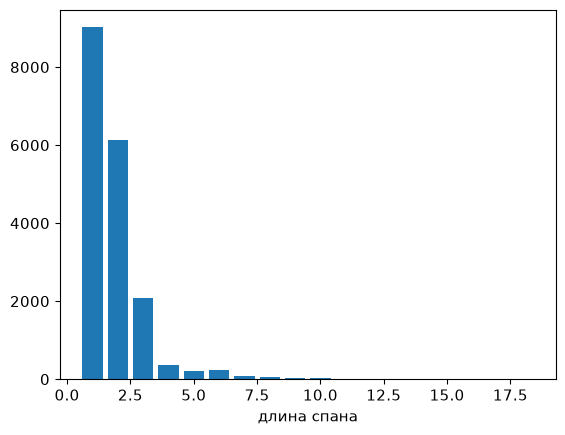

In [15]:
span_lens = collections.Counter()
for split in raw:
    cnt = collections.Counter()
    for tags in raw[split]['ner_tags']:
        for i, t in enumerate(tags):
            name = LABEL_NAMES[t]
            if name.startswith('B-'):
                cnt[name[2:]] += 1
                if split == 'train':
                    j = i + 1
                    while j < len(tags) and LABEL_NAMES[tags[j]] == 'I-' + name[2:]:
                        j += 1
                    span_lens[j - i] += 1
    lens = [len(x) for x in raw[split]['tokens']]
    print(split, len(raw[split]), dict(cnt), 'длина предложения: средняя', round(np.mean(lens), 1), 'макс', max(lens))

print('длины спанов в train:', dict(sorted(span_lens.items())))
plt.bar(list(span_lens.keys()), list(span_lens.values()))
plt.xlabel('длина спана')
plt.show()

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** Collection3 - русские новости от RCC MSU, размечены вручную, типы PER, ORG, LOC. лицензия в карточке не указана. train 9301 предложение (PER 7405, ORG 5956, LOC 4881), validation 2153 (1641 / 1308 / 1168), test 1922 (1570 / 1255 / 1175). совсем редких типов нет, LOC чуть меньше. спаны короткие: половина (49.5%) из одного слова, 33.6% из двух, но есть длинные до 18 слов - это в основном организации с названиями в кавычках. предложения в среднем 20 слов, максимум 256, так что почти ничего не обрежется по 128 сабвордам. на обучение скорее всего повлияют длинные ORG с кавычками (непонятно где граница) и немного кривой разметки (есть I- без B-, см. 2.2).

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [16]:
def bio_to_spans(tags):
    # ['B-PER', 'I-PER', 'O', 'B-LOC'] -> [(0, 2, 'PER'), (3, 4, 'LOC')]
    spans = []
    start, typ = None, None
    for i, t in enumerate(tags):
        if t == 'O':
            if start is not None:
                spans.append((start, i, typ))
            start = None
        elif t.startswith('B-') or start is None or t[2:] != typ:
            if start is not None:
                spans.append((start, i, typ))
            start, typ = i, t[2:]
    if start is not None:
        spans.append((start, len(tags), typ))
    return spans


def spans_to_bio(spans, n_words):
    # [(0, 2, 'PER')], 3 -> ['B-PER', 'I-PER', 'O']
    tags = ['O'] * n_words
    for s, e, t in spans:
        tags[s] = 'B-' + t
        for i in range(s + 1, e):
            tags[i] = 'I-' + t
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    # word_labels: id тегов слов; word_ids: номер слова для каждого сабворда (None - спецтокен) -> метки сабвордов
    res = []
    prev = None
    for w in word_ids:
        if w is None:
            res.append(-100)
        elif w != prev:
            res.append(word_labels[w])
        elif b_to_i is None:
            res.append(-100)
        else:
            res.append(b_to_i.get(word_labels[w], word_labels[w]))
        prev = w
    return res

In [17]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [18]:
os.makedirs('data', exist_ok=True)
for split in raw:
    with open(f'data/{split}_spans.jsonl', 'w') as f:
        for ex in raw[split]:
            tags = [LABEL_NAMES[t] for t in ex['ner_tags']]
            f.write(json.dumps({'tokens': ex['tokens'], 'spans': bio_to_spans(tags)}, ensure_ascii=False) + '\n')

    same, same_spans = 0, 0
    with open(f'data/{split}_spans.jsonl') as f:
        for line, ex in zip(f, raw[split]):
            d = json.loads(line)
            spans = [tuple(s) for s in d['spans']]
            back = spans_to_bio(spans, len(d['tokens']))
            orig = [LABEL_NAMES[t] for t in ex['ner_tags']]
            same += back == orig
            same_spans += bio_to_spans(back) == bio_to_spans(orig)
    print(split, len(raw[split]), 'совпало BIO:', same, 'совпали спаны:', same_spans)

train 9301 совпало BIO: 9296 совпали спаны: 9301
validation 2153 совпало BIO: 2153 совпали спаны: 2153
test 1922 совпало BIO: 1921 совпали спаны: 1922


In [19]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None else ds.shuffle(seed=SEED).select(range(min(n, len(ds))))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_truncated = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_truncated += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, обрезано по MAX_LENGTH {n_truncated}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

Map:   0%|          | 0/9301 [00:00<?, ? examples/s]

Map:   0%|          | 0/2153 [00:00<?, ? examples/s]

Map:   0%|          | 0/1922 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 9301
    })
    validation: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 2153
    })
    test: Dataset({
        features: ['id', 'tokens', 'ner_tags'],
        num_rows: 1922
    })
})
ENTITY_TYPES ['LOC', 'ORG', 'PER']


train: проверено 9288 предложений, обрезано по MAX_LENGTH 10, слов без сабвордов или за обрезкой 434
[CLS]            None  -100
До                  0  O
##полнение          0  -100
:                   1  O
Д                   2  B-PER
.                   3  I-PER
Медведев            4  I-PER
присвоил            5  O
звания              6  O
сотрудников         7  O
полиции             8  O
и                   9  O
перена             10  O
##зна              10  -100
##чил              10  -100
14                 11  O
руководителей      12  O
УВД                13  B-ORG
,                  14  O
ГУВД               15  B-ORG
и                  16  O
МВД                17  B-ORG
по                 18  O
субъектам          19  O
РФ                 20  B-LOC
.                  21  O
[SEP]            None  -100


**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:** метрика по словам, поэтому на слово нужен один тег - ставим на первый сабворд, остальным -100. -100 это ignore_index в cross entropy, эти позиции не дают loss и градиента, иначе длинные слова весили бы больше. обрезано по MAX_LENGTH 10 предложений train, без сабвордов осталось 434 слова (это хвосты этих длинных предложений), им ставится O, на метрику это почти не влияет (434 из ~188к слов). датасет уже в BIO, выгрузил в спаны jsonl и обратно: спаны совпали везде, а BIO дословно не совпал в 5 предложениях train и 1 test - там в исходнике I- без B-, обратная конвертация делает из них B-. вложенных спанов в таком формате нет.

---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [20]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [21]:
def fit_majority_tagger(tokens_list, tags_list):
    # -> dict: слово -> самый частый тег этого слова в train
    cnt = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list):
        for w, t in zip(words, tags):
            cnt[w][t] += 1
    return {w: c.most_common(1)[0][0] for w, c in cnt.items()}


def predict_majority(tagger, words):
    # -> список тегов той же длины; незнакомое слово -> 'O'
    return [tagger.get(w, 'O') for w in words]

In [22]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []

baseline = {}
train_tags = [[LABEL_NAMES[t] for t in tags] for tags in data['train']['ner_tags']]
tagger = fit_majority_tagger(data['train']['tokens'], train_tags)
baseline['majority'] = entity_scores(val_gold, [predict_majority(tagger, ws) for ws in val_tokens])

set_seed(SEED)
rand_model = make_model()
baseline['random_head'] = entity_scores(val_gold, predict_word_tags(rand_model, val_tokens))
baseline

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'majority': {'f1_micro': np.float64(0.5613437195715676),
  'f1_macro': np.float64(0.5785510074917143),
  'precision': np.float64(0.5625762381068553),
  'recall': np.float64(0.5601165897498178)},
 'random_head': {'f1_micro': np.float64(0.0380824055031558),
  'f1_macro': np.float64(0.035254710988307),
  'precision': np.float64(0.022296034876479135),
  'recall': np.float64(0.13043478260869565)}}

**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:** у словарного бейзлайна F1 0.561 на validation (P 0.563, R 0.560). в новостях сущности часто повторяются (страны, МВД, Путин и т.д.), поэтому что-то он находит, но незнакомые слова всегда O, тег не зависит от контекста, и B/I запоминаются по слову, а не по позиции, так что многословные спаны часто собираются с неправильными границами, а seqeval засчитывает только точное совпадение. энкодер со случайной головой - F1 0.038: голова Linear(312, 7) случайная и ничего не знает про наши теги, предсказывает почти рандомную кашу из тегов (recall 0.13, precision 0.02). энкодер предобучен, но связь признаков с тегами надо выучить.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [23]:
LR = 2e-4
BATCH_SIZE = 32


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer
    if freeze_encoder:
        for p in model.bert.parameters():
            p.requires_grad = False
    steps = math.ceil(len(train_ds) / batch_size) * epochs
    args = TrainingArguments(out_dir, num_train_epochs=epochs, learning_rate=lr,
                             per_device_train_batch_size=batch_size, per_device_eval_batch_size=128,
                             warmup_steps=steps // 10, weight_decay=0.01,
                             eval_strategy='steps', eval_steps=steps // 20, logging_steps=steps // 20,
                             save_strategy='no', report_to='none', fp16=torch.cuda.is_available(), disable_tqdm=True, seed=SEED)
    trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=eval_ds,
                      data_collator=DataCollatorForTokenClassification(tok), processing_class=tok)
    t = time.time()
    trainer.train()
    return trainer.state.log_history, time.time() - t

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

/Users/mikhailshperling/Downloads/dl-hw/.venv/lib/python3.13/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{'loss': '1.12', 'grad_norm': '1.126', 'learning_rate': '9.655e-05', 'epoch': '0.1478'}


{'eval_loss': '0.4127', 'eval_runtime': '2.591', 'eval_samples_per_second': '831', 'eval_steps_per_second': '6.562', 'epoch': '0.1478'}


{'loss': '0.2765', 'grad_norm': '1.215', 'learning_rate': '0.0001954', 'epoch': '0.2955'}


{'eval_loss': '0.137', 'eval_runtime': '3.269', 'eval_samples_per_second': '658.6', 'eval_steps_per_second': '5.2', 'epoch': '0.2955'}


... (33 outputs left out)

{'eval_loss': '0.04064', 'eval_runtime': '3.221', 'eval_samples_per_second': '668.4', 'eval_steps_per_second': '5.278', 'epoch': '2.808'}


{'loss': '0.01825', 'grad_norm': '0.6808', 'learning_rate': '3.562e-06', 'epoch': '2.955'}


{'eval_loss': '0.0413', 'eval_runtime': '4.064', 'eval_samples_per_second': '529.8', 'eval_steps_per_second': '4.183', 'epoch': '2.955'}


{'eval_loss': '0.04127', 'eval_runtime': '2.631', 'eval_samples_per_second': '818.2', 'eval_steps_per_second': '6.461', 'epoch': '3'}
{'train_runtime': '272.3', 'train_samples_per_second': '102.5', 'train_steps_per_second': '3.206', 'train_loss': '0.1108', 'epoch': '3'}
обучение: 272.5 c на mps, 9301 предложений, 3 эпох(а)


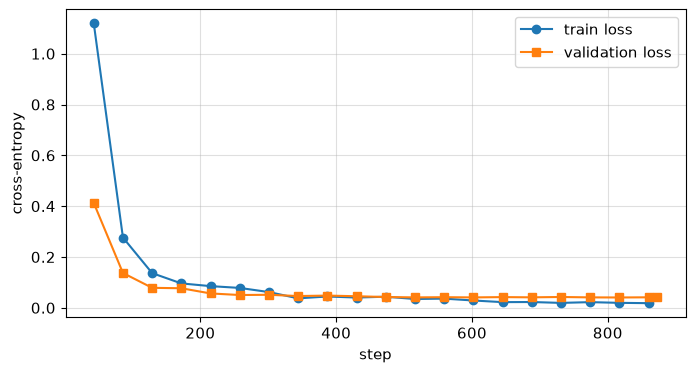

In [24]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:** lr 2e-4 потому что модель маленькая и ей нужен lr побольше чем 2e-5 у base моделей, batch 32, 3 эпохи, warmup 10%, weight decay 0.01, fp16 нет (на маке). train loss падает с 1.1 до ~0.02, validation loss падает до ~0.04 к середине второй эпохи и дальше стоит на месте, а train продолжает падать - то есть начинается переобучение, но val не растет. больше эпох вряд ли поможет, скорее хватило бы 2. обучение заняло 272 с на M4 Pro (mps).

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [25]:
def token_f1(gold, pred):
    # gold, pred: списки списков BIO-тегов -> micro-F1 по словам без тега O
    tp = fp = fn = 0
    for gs, ps in zip(gold, pred):
        for g, p in zip(gs, ps):
            if p != 'O' and p == g:
                tp += 1
            else:
                if p != 'O':
                    fp += 1
                if g != 'O':
                    fn += 1
    if tp == 0:
        return 0.0
    return 2 * tp / (2 * tp + fp + fn)

In [26]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0

val_pred = predict_word_tags(model, val_tokens)
print('validation')
print(classification_report(val_gold, val_pred, digits=4))
print('val token f1', token_f1(val_gold, val_pred))

test_tokens = [list(ws) for ws in data['test']['tokens']]
test_gold = [[LABEL_NAMES[t] for t in tags] for tags in data['test']['ner_tags']]
test_pred = predict_word_tags(model, test_tokens)
print('test')
print(classification_report(test_gold, test_pred, digits=4))

final = entity_scores(test_gold, test_pred)
final['token_f1'] = token_f1(test_gold, test_pred)
rep = classification_report(test_gold, test_pred, output_dict=True)
final['per_type'] = {t: rep[t] for t in ENTITY_TYPES}
final

validation


              precision    recall  f1-score   support

         LOC     0.9585    0.9495    0.9540      1168
         ORG     0.8303    0.8976    0.8626      1308
         PER     0.9642    0.9842    0.9741      1641

   micro avg     0.9180    0.9468    0.9322      4117
   macro avg     0.9177    0.9437    0.9302      4117
weighted avg     0.9200    0.9468    0.9330      4117

val token f1 0.9529074529074529


test


              precision    recall  f1-score   support

         LOC     0.9480    0.9617    0.9548      1175
         ORG     0.8387    0.8734    0.8557      1256
         PER     0.9565    0.9809    0.9686      1570

   micro avg     0.9165    0.9415    0.9289      4001
   macro avg     0.9144    0.9387    0.9263      4001
weighted avg     0.9170    0.9415    0.9291      4001



{'f1_micro': np.float64(0.9288620392060164),
 'f1_macro': np.float64(0.9263475953901329),
 'precision': np.float64(0.9165450121654501),
 'recall': np.float64(0.9415146213446638),
 'token_f1': 0.9539302802460697,
 'per_type': {'LOC': {'precision': np.float64(0.947986577181208),
   'recall': np.float64(0.9617021276595744),
   'f1-score': np.float64(0.9547950992817913),
   'support': np.int64(1175)},
  'ORG': {'precision': np.float64(0.8386850152905199),
   'recall': np.float64(0.8734076433121019),
   'f1-score': np.float64(0.8556942277691107),
   'support': np.int64(1256)},
  'PER': {'precision': np.float64(0.9565217391304348),
   'recall': np.float64(0.9808917197452229),
   'f1-score': np.float64(0.9685534591194969),
   'support': np.int64(1570)}}}

**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:** хуже всего ORG: F1 на test 0.856 (P 0.839, R 0.873), у LOC 0.955 и PER 0.969. организации длинные и разнообразные (названия в кавычках, аббревиатуры, "Змиевская районная администрация"), и их часто путают с LOC (G20, МВД РФ). micro F1 0.929 и macro 0.926 почти одинаковые, т.к. классы примерно сбалансированы, micro чуть выше потому что самый частый PER распознается лучше всех. токенный F1 выше - 0.954 против 0.929, потому что если ошибиться с границей на одно слово, в токенном F1 теряется одно слово, а по сущностям весь спан. для пользователя важнее F1 по сущностям, ему нужно целое название, а не кусок.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [27]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    # -> [(категория, gold-спан или None, pred-спан или None), ...]
    def inter(a, b):
        return a[0] < b[1] and b[0] < a[1]

    res = []
    for g in gold_spans:
        if g in pred_spans:
            res.append(('correct', g, g))
            continue
        same = [p for p in pred_spans if inter(g, p) and p[2] == g[2]]
        other = [p for p in pred_spans if inter(g, p) and p[2] != g[2]]
        if same:
            res.append(('boundary', g, same[0]))
        elif other:
            res.append(('type', g, other[0]))
        else:
            res.append(('missed', g, None))
    for p in pred_spans:
        if not any(inter(g, p) for g in gold_spans):
            res.append(('spurious', None, p))
    return res

In [28]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются

errors = {c: 0 for c in ERROR_CATEGORIES}
err_types = collections.Counter()
examples = []
for i in range(len(val_tokens)):
    for c, g, p in categorize_errors(bio_to_spans(val_gold[i]), bio_to_spans(val_pred[i])):
        errors[c] += 1
        if c != 'correct':
            err_types[(c, (g or p)[2])] += 1
            examples.append((c, i, g, p))
print(errors)
n_err = sum(errors.values()) - errors['correct']
print({c: round(errors[c] / n_err, 3) for c in ERROR_CATEGORIES[1:]})
print(err_types)

random.seed(0)
for c in ERROR_CATEGORIES[1:]:
    print('-----', c)
    for _, i, g, p in random.sample([e for e in examples if e[0] == c], 3):
        words = val_tokens[i]
        print(' '.join(words))
        print('   gold:', g and ' '.join(words[g[0]:g[1]]), g, '  pred:', p and ' '.join(words[p[0]:p[1]]), p)

{'correct': 3898, 'boundary': 148, 'type': 50, 'missed': 21, 'spurious': 126}
{'boundary': 0.429, 'type': 0.145, 'missed': 0.061, 'spurious': 0.365}
Counter({('boundary', 'ORG'): 113, ('spurious', 'ORG'): 98, ('type', 'LOC'): 36, ('spurious', 'LOC'): 21, ('boundary', 'PER'): 19, ('boundary', 'LOC'): 16, ('missed', 'ORG'): 12, ('type', 'ORG'): 9, ('spurious', 'PER'): 7, ('missed', 'LOC'): 7, ('type', 'PER'): 5, ('missed', 'PER'): 2})
----- boundary
После получения денег Гусев , используя свое служебное положение , присвоил их себе , не передав в кассу бухгалтерии ГП " Медынский лесхоз " .
   gold: ГП " Медынский лесхоз " (19, 24, 'ORG')   pred: ГП " Медынский лесхоз (19, 23, 'ORG')
Читайте также : В Румынии Конституционный суд поддержал импичмент Президенту
   gold: суд (6, 7, 'ORG')   pred: Конституционный суд (5, 7, 'ORG')
В частности , начальником НПО " Специальная техника и связь " вместо уволенного в прошлом году Александра Квитко стал Михаил Муганов .
   gold: НПО " Специальная те

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:** на validation 3898 правильных и 345 ошибок: boundary 148 (43%), spurious 126 (36.5%), type 50 (14.5%), missed 21 (6%). самое частое - ошибки границ, почти все в ORG (113 из 148): модель не берет закрывающую кавычку (ГП " Медынский лесхоз " -> без последней кавычки) или наоборот берет лишнее (Конституционный суд, а в разметке только "суд"). лишние спаны тоже в основном ORG (98): "центра", "Окружение", "ДМ" (это разгонный блок). ошибки типа - G20 как LOC, Томск в цитате размечен LOC а модель сказала ORG, Лихтенштейне -> PER. часть ошибок по-моему ошибки разметки: "Ваш" как PER, "суд" без "Конституционный", кавычки в ORG размечены непоследовательно. чтобы уменьшить ошибки границ, можно сделать правило что ORG расширяется до парной кавычки, или взять модель побольше / CRF сверху.

## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [29]:
ABLATION = 'freeze'
set_seed(SEED)
model_frozen = make_model()
_, sec_frozen = train_ner(model_frozen, tokenized['train'], tokenized['validation'], freeze_encoder=True, out_dir='runs/freeze')
pred_frozen = predict_word_tags(model_frozen, val_tokens)

ablation = {
    'setting': ABLATION,
    'full': entity_scores(val_gold, val_pred) | {'sec': RUN_TIMES['train_main_sec'],
                                                 'trainable': sum(p.numel() for p in model.parameters() if p.requires_grad)},
    'freeze': entity_scores(val_gold, pred_frozen) | {'sec': sec_frozen,
                                                      'trainable': sum(p.numel() for p in model_frozen.parameters() if p.requires_grad)},
}
ablation

Loading weights:   0%|          | 0/53 [00:00<?, ?it/s]

{'loss': '1.783', 'grad_norm': '4.283', 'learning_rate': '9.655e-05', 'epoch': '0.1478'}


{'eval_loss': '1.634', 'eval_runtime': '4.586', 'eval_samples_per_second': '469.5', 'eval_steps_per_second': '3.707', 'epoch': '0.1478'}


{'loss': '1.393', 'grad_norm': '2.92', 'learning_rate': '0.0001954', 'epoch': '0.2955'}


{'eval_loss': '1.094', 'eval_runtime': '3.38', 'eval_samples_per_second': '637', 'eval_steps_per_second': '5.03', 'epoch': '0.2955'}


{'loss': '0.9025', 'grad_norm': '1.221', 'learning_rate': '0.0001896', 'epoch': '0.4433'}


... (33 outputs left out)

{'loss': '0.298', 'grad_norm': '0.3053', 'learning_rate': '3.562e-06', 'epoch': '2.955'}


{'eval_loss': '0.2608', 'eval_runtime': '2.506', 'eval_samples_per_second': '859', 'eval_steps_per_second': '6.783', 'epoch': '2.955'}


{'eval_loss': '0.2607', 'eval_runtime': '2.854', 'eval_samples_per_second': '754.3', 'eval_steps_per_second': '5.956', 'epoch': '3'}
{'train_runtime': '184.6', 'train_samples_per_second': '151.2', 'train_steps_per_second': '4.729', 'train_loss': '0.5195', 'epoch': '3'}


{'setting': 'freeze',
 'full': {'f1_micro': np.float64(0.932201363147196),
  'f1_macro': np.float64(0.9302148873334692),
  'precision': np.float64(0.9180405087140838),
  'recall': np.float64(0.9468059266456157),
  'sec': 272.4531650543213,
  'trainable': 29098303},
 'freeze': {'f1_micro': np.float64(0.6154037886340976),
  'f1_macro': np.float64(0.5973449729319752),
  'precision': np.float64(0.6319426670079344),
  'recall': np.float64(0.5997085256254554),
  'sec': 190.4258849620819,
  'trainable': 2191}}

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:** заморозил энкодер (учится только голова, 2191 параметр вместо 29М) с тем же lr и эпохами: F1 на validation упал с 0.932 до 0.615, время 272 -> 190 с (backward через энкодер не нужен, но forward все равно идет). видимо признаки маленького энкодера после предобучения линейно не разделяются на BIO-теги, границы спанов он не знает. но val loss у замороженной еще падал, так что часть разницы - недообучение при маленьком для головы lr. следующим шагом дал бы замороженной lr побольше (1e-3) и больше эпох, и прогнал бы оба варианта на нескольких сидах.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:** дообученный rubert-tiny2 дает на test F1 по сущностям 0.929 (токенный 0.954), против 0.561 у словаря и 0.038 у случайной головы, и учится всего ~4.5 минуты на маке. PER и LOC почти идеально (0.969 и 0.955), проблема в ORG (0.856) - на них большинство ошибок границ и лишних спанов. дообучать надо всю модель, с замороженным энкодером только 0.615. модель сильно зависит от регистра: lower/upper/транслит роняют F1 до 0.07-0.13 (бонус 6.3). ограничения: один небольшой датасет из новостей, неаккуратная разметка кавычек, маленькая модель, один сид. дальше попробовал бы rubert-base, аугментацию регистром и несколько сидов.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [30]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    baseline=baseline, final=final, ablation=ablation, errors=errors,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "cointegrated/rubert-tiny2", "revision": "e8ed3b0c8bbf4fb6984c3de043bf7d2f4e5969ae", "dataset": "RCC-MSU/collection3", "classes": ["LOC", "ORG", "PER"], "n_train": 9301, "n_val": 2153, "n_test": 1922, "params_total": 29098303, "ablation": {"setting": "freeze", "full": {"f1_micro": 0.932201363147196, "f1_macro": 0.9302148873334692, "precision": 0.9180405087140838, "recall": 0.9468059266456157, "sec": 272.4531650543213, "trainable": 29098303}, "freeze": {"f1_micro": 0.6154037886340976, "f1_macro": 0.5973449729319752, "precision": 0.6319426670079344, "recall": 0.59970852
final F1 micro 0.9289


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [31]:
if '6.1' in BONUS_TASKS:
    # ваш код
    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:** не делал

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [32]:
if '6.2' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:** не делал

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [33]:
if '6.3' in BONUS_TASKS:
    def typos(ws):
        res = []
        for w in ws:
            if len(w) > 3 and random.random() < 0.15:
                i = random.randrange(len(w) - 1)
                w = w[:i] + w[i + 1] + w[i] + w[i + 2:]
            res.append(w)
        return res

    lat = 'a b v g d e e zh z i y k l m n o p r s t u f kh ts ch sh shch  y  e yu ya'.split(' ')
    tr = dict(zip('абвгдеёжзийклмнопрстуфхцчшщъыьэюя', lat))

    def translit(ws):
        res = []
        for w in ws:
            t = ''.join(tr.get(ch.lower(), ch) for ch in w)
            if w[:1].isupper():
                t = t.capitalize()
            res.append(t or w)
        return res

    random.seed(0)
    shift = {}
    for name, f in [('clean', lambda ws: ws), ('lower', lambda ws: [w.lower() for w in ws]),
                    ('upper', lambda ws: [w.upper() for w in ws]), ('typos', typos), ('translit', translit)]:
        toks = [f(ws) for ws in val_tokens]
        shift[name] = entity_scores(val_gold, predict_word_tags(model, toks))
        print(name, shift[name], 'сабвордов на слово', np.mean([len(tokenizer.tokenize(w)) for ws in toks[:300] for w in ws]))

clean {'f1_micro': np.float64(0.932201363147196), 'f1_macro': np.float64(0.9302148873334692), 'precision': np.float64(0.9180405087140838), 'recall': np.float64(0.9468059266456157)} сабвордов на слово 1.143524699599466


lower {'f1_micro': np.float64(0.07769532955041467), 'f1_macro': np.float64(0.07159599805941651), 'precision': np.float64(0.3827956989247312), 'recall': np.float64(0.04323536555744474)} сабвордов на слово 1.2419893190921227


upper {'f1_micro': np.float64(0.06626708869284127), 'f1_macro': np.float64(0.07027205900475499), 'precision': np.float64(0.04584420424897503), 'recall': np.float64(0.11950449356327422)} сабвордов на слово 3.4742990654205608


typos {'f1_micro': np.float64(0.8816793893129772), 'f1_macro': np.float64(0.8799592503847068), 'precision': np.float64(0.8661823295055073), 'recall': np.float64(0.8977410735972796)} сабвордов на слово 1.305407209612817


translit {'f1_micro': np.float64(0.12813370473537603), 'f1_macro': np.float64(0.12318487956029951), 'precision': np.float64(0.08813064501414104), 'recall': np.float64(0.2346368715083799)} сабвордов на слово 2.4627837116154874


**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:** опечатки (переставил соседние буквы в 15% слов) роняют несильно: 0.932 -> 0.882. а регистр и транслит убивают модель: lower 0.078, upper 0.066, транслит 0.128. модель cased и заглавная буква для нее главный признак сущности: в нижнем регистре она почти ничего не находит (recall 0.04), а в верхнем все слова выглядят как аббревиатуры типа МВД и она размечает кучу мусора (precision 0.05). плюс ломается токенизация: upper режется на 3.5 сабворда на слово вместо 1.14, транслит на 2.5, и модель видит незнакомые куски. опечатка портит одно слово и заглавную букву обычно не трогает, поэтому влияет мало.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [34]:
if '6.4' in BONUS_TASKS:
    # ваш код
    raise NotImplementedError

**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:** не делал

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

mean порог 0: F1 0.9322 | лучший порог 0.79 F1 0.9377 P 0.943 R 0.9325
min порог 0: F1 0.9322 | лучший порог 0.67 F1 0.9371 P 0.9395 R 0.9347


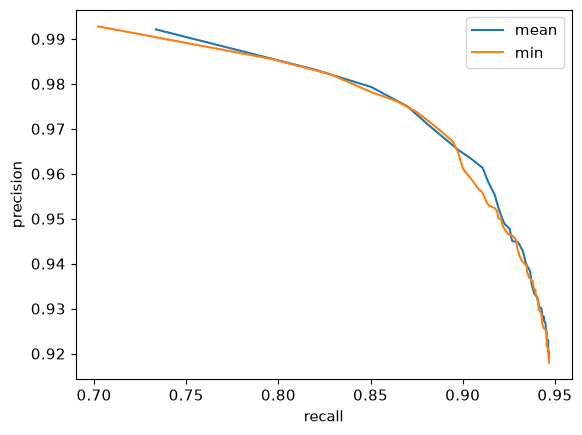

In [35]:
if '6.5' in BONUS_TASKS:
    tags_p, probs_p = predict_word_tags(model, val_tokens, return_probs=True)
    gold_sp = [set(bio_to_spans(g)) for g in val_gold]
    n_gold = sum(len(g) for g in gold_sp)
    sp = []
    for i in range(len(tags_p)):
        for s, e, t in bio_to_spans(tags_p[i]):
            sp.append((i, (s, e, t), np.mean(probs_p[i][s:e]), np.min(probs_p[i][s:e])))

    ths = np.arange(0, 1, 0.01)
    for k, name in [(2, 'mean'), (3, 'min')]:
        P, R, F = [], [], []
        for th in ths:
            kept = [x for x in sp if x[k] >= th]
            tp = sum(x[1] in gold_sp[x[0]] for x in kept)
            p = tp / len(kept) if kept else 1
            r = tp / n_gold
            P.append(p); R.append(r); F.append(2 * p * r / (p + r) if tp else 0)
        b = int(np.argmax(F))
        print(name, 'порог 0: F1', round(F[0], 4), '| лучший порог', round(ths[b], 2), 'F1', round(F[b], 4), 'P', round(P[b], 4), 'R', round(R[b], 4))
        plt.plot(R, P, label=name)
    plt.xlabel('recall')
    plt.ylabel('precision')
    plt.legend()
    plt.show()

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:** лучший порог по средней уверенности 0.79: F1 0.9377 против 0.9322 при пороге 0, т.е. +0.0055 (precision 0.918 -> 0.943, recall 0.947 -> 0.933). по минимальной уверенности лучший порог 0.67, F1 0.9371. минимальная строже - выкидывает весь спан если хоть одно слово неуверенное, поэтому порог у нее ниже. recall порогом поднять нельзя, мы только выкидываем предсказанные спаны, новых правильных не появляется. порог подбирал на validation, на test прирост может быть меньше.